In [ ]:
# Setup: download the data (needed in Google Colab, skipped if the file already exists)
import os, urllib.request

BASE = "https://raw.githubusercontent.com/BRCCH-2026/BRCCH-2026/main/"
for f in ["heart_disease_data.csv"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)

# Basics of Data visualization with python

**Definition**: The art of communicating meaningful data visually. This can involve infographics, traditional plots, or even full data dashboards. Some tips for data visualization: 

* Choose a consistent  graph type for each data type
* Always include plot title, axis titles, and units. Include a legend when applicable. 
* Use appropriate colors and color palettes. Think about how they will affect a color blind audience. Divergent colormaps can be useful to enhance differences, whereas sequential colormaps are more appropriate for progression data. 


## Why is Data Visualization important? 

Descriptive statistics can give an idea about how the data is, but very similar data can still look very different.

![gif_dino](https://damassets.autodesk.net/content/dam/autodesk/research/publications-assets/gifs/same-stats-different-graphs/DinoSequentialSmaller.gif)

Data Source: https://www.autodesk.com/research/publications/same-stats-different-graphs

## A simple example

Matplotlib graphs your data on `.Figure`\s (e.g., windows, Jupyter
widgets, etc.), each of which can contain one or more `~.axes.Axes`, an
area where points can be specified in terms of x-y coordinates (or theta-r
in a polar plot, x-y-z in a 3D plot, etc.).  The simplest way of
creating a Figure with an Axes is using `.pyplot.subplots`. We can then use
`.Axes.plot` to draw some data on the Axes, and `~.pyplot.show` to display
the figure.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

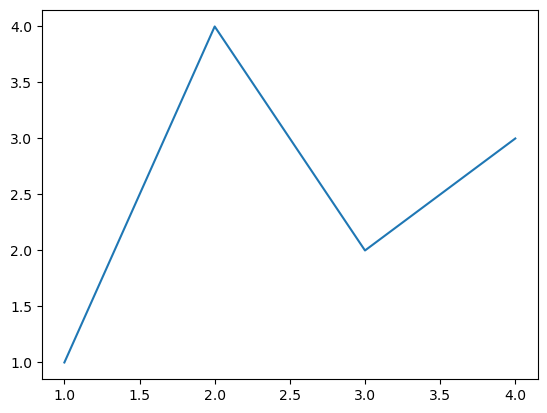

In [2]:
fig, ax = plt.subplots()             # Create a figure containing a single Axes.
ax.plot([1, 2, 3, 4], [1, 4, 2, 3])  # Plot some data on the Axes.
plt.show()                           # Show the figure.

Depending on the environment you are working in, ``plt.show()`` can be left
out. This is for example the case with Jupyter notebooks, which
automatically show all figures created in a code cell.



## Mapping data onto aesthetics
Aesthetics refers to the visual appeal of a graphic. They describe every aspect of a given graphical element such as position, shape, size, color, line width, line type. Some of these aesthetics can represent both continuous and discrete data (position, size, line width, color) while others can usually only represent discrete data (shape, line type).

<img src="https://clauswilke.com/dataviz/aesthetic_mapping_files/figure-html/common-aesthetics-1.png" width="640" align="center" />


Data Source: https://clauswilke.com/dataviz/aesthetic-mapping.html


### Parts of a Figure

Most of the aspects of a figure can be customized. Some examples are shown below. 

<img src="simple_anatomy.png" alt="Description" width="500">

For further exploration of the components of a Matplotlib Figure, please refer to the following documentation: https://matplotlib.org/stable/api/axes_api.html

## Creating subplots

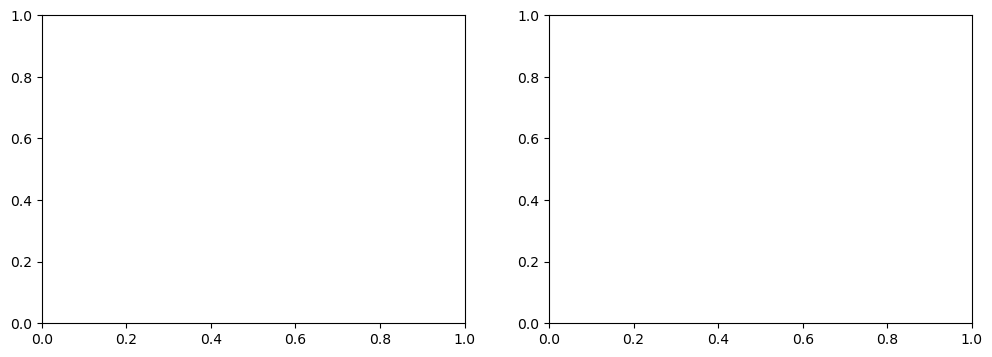

In [3]:
# Create a Figure and two axes (ax1, ax2) with plt.subplots and figure size (12,4)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12,4))

# ax1 and ax2 are an empty set of axes
plt.show()

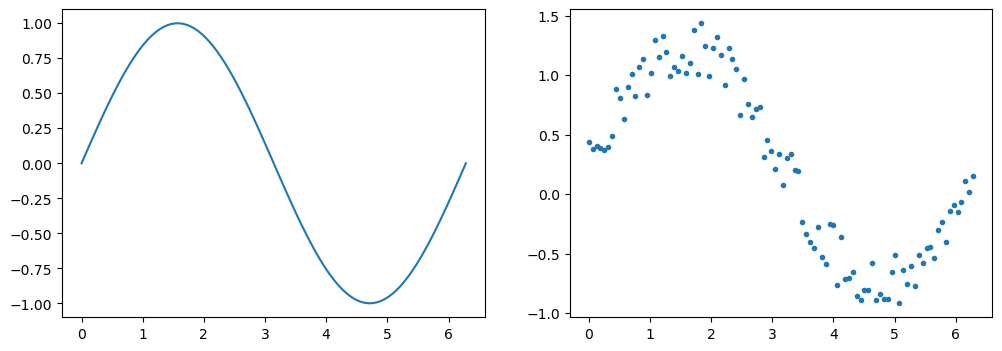

In [4]:
# Create a vector to use for the x-axis
x = np.linspace(0, 2*np.pi, 100)
y =  np.sin(x)

# Plot a line 
line1, = ax1.plot(x, y, label="sin(x)")

# Create random noise points and add them to the y-function
z = y + 0.5 * np.random.rand(len(x))

# Create the representation as scatter points
p1 = ax2.scatter(x, z, marker=".")

# In jupyter, you can also just call the figure to show the result
fig

## Exercise 1: add a second data series to the existing figure

Task:
1. Generate the cosine function y2 = cos(x) and a noisy version z2 (add uniform noise scaled by 0.2 to y2).
2. On ax1, plot y2 as a red line with linewidth 3 and the label "cos(x)". Keep the Line2D object returned by the call in `line2`.
3. On ax2, draw z2 as a scatter plot with red "x" markers, marker size 15 and linewidth 1. Keep the returned object in `p2`.
4. Display the updated figure.

Hints (matplotlib docs):
- Axes.plot:    https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html
                 (note: plot() returns a *list* of Line2D objects)
- Axes.scatter: https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html
                 (see the parameters `marker`, `s`, `c`/`color`, `linewidths`)
- Marker styles: https://matplotlib.org/stable/api/markers_api.html
- np.random.rand: https://numpy.org/doc/stable/reference/random/generated/numpy.random.rand.html

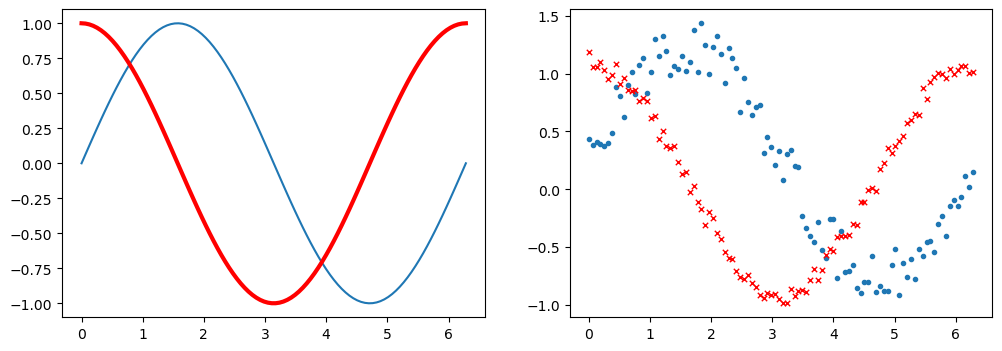

In [5]:
# 1. Generate the cosine data
y2 = np.cos(x)
z2 = y2 + 0.2 * np.random.rand(len(x))

# 2. Add the cosine line to ax1
line2, = ax1.plot(x, y2,  color="red", linewidth=3, label="cos(x)")

# 3. Add the noisy scatter points to ax2
p2 = ax2.scatter(x, z2, marker="x", s=15, color="red",linewidth=1)

# 4. Show the updated figure
fig

## Working with real world data

We are going to work with the heart disease dataset. It contains clinical data from 303 patients, including demographics (age, sex), symptoms, resting measurements (blood pressure, cholesterol), and exercise test results. The target variable `num` indicates the presence and severity of heart disease.

We will explore the dataset through visualization. We examine the distributions of key features and compare them between patients with and without heart disease to identify patterns and potential risk factors.

In [6]:
# Load the heart disease dataset into a DataFrame
df = pd.read_csv('./heart_disease_data.csv', index_col=0)

We use both **matplotlib** and **seaborn** in this notebook. Matplotlib is the foundation of Python plotting and gives full control over every element of a figure. Seaborn is built on top of it and offers a concise, high-level interface for statistical plots, such as grouping by category, with sensible default styling. Please refer to the seaborn documentation: https://seaborn.pydata.org/api.html

Working with both lets us compare the two approaches, use seaborn for quick exploratory plots, and fall back on matplotlib when we need finer customization.

As a first example, we plot the count of each data type in the dataset with both libraries.

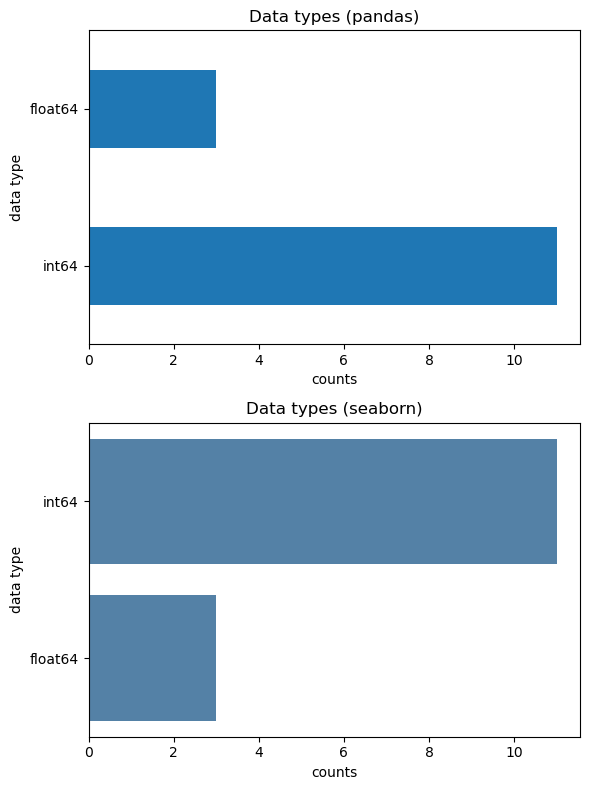

In [7]:
# Count of each data type
dtype_counts = df.dtypes.value_counts()

# Two rows, one column
fig, axes = plt.subplots(2, 1, figsize=(6, 8))

# Subplot 1: pandas built-in
dtype_counts.plot.barh(ax=axes[0])
axes[0].set(
    title="Data types (pandas)",
    xlabel="counts",
    ylabel="data type"
)

# Subplot 2: seaborn
sns.barplot(
    x=dtype_counts.values,
    y=dtype_counts.index.astype(str),
    orient='h',
    ax=axes[1],
    color='steelblue'
)
axes[1].set(
    title="Data types (seaborn)",
    xlabel="counts",
    ylabel="data type"
)

# Adjust the layout
plt.tight_layout()
plt.show()

### Distributions and group comparisons

Let's have a look at the data.

In [8]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')

In [9]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


We need to clean up a few variables before we start plotting them.

In [10]:
df['sex'].value_counts()

sex
1    206
0     97
Name: count, dtype: int64

In [11]:
df['sex'] = df['sex'].map({0: 'female', 1: 'male'})

In [12]:
df['cp'].value_counts()

cp
4    144
3     86
2     50
1     23
Name: count, dtype: int64

In [13]:
df['cp'] = df['cp'].map({
    1: 'typical angina',
    2: 'atypical angina',
    3: 'non-anginal pain',
    4: 'asymptomatic'
})

In [14]:
df['num'].value_counts()

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [15]:
df['num'] = df['num'].map({0:'No', 1:'Yes', 2:'Yes', 3:'Yes', 4:'Yes'})

df = df.rename(columns={'num': 'heart_failure'})

In [16]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'heart_failure'],
      dtype='object')

A `histogram` is a plot that lets you discover and show the underlying frequency distribution of a set of continuous data.

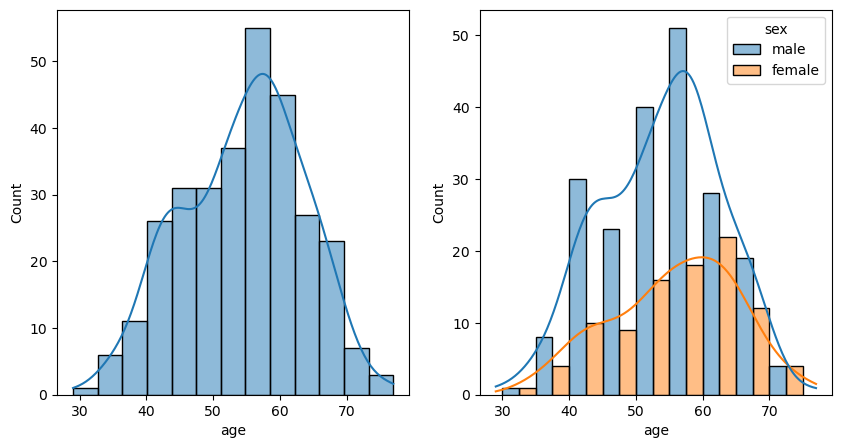

In [17]:
fig_age, axes = plt.subplots(1, 2, figsize=(10,5))

# For the rest of visualizations with seaborn, we will use the predefined colorblind palette
colorblind_palete = sns.color_palette("colorblind") 

fig_age_normal = sns.histplot(
    df, 
    x = 'age', 
    ax=axes[0],
    kde=True
)

# Plot the histogram using the gender for color coding
fig_age_custom_bins = sns.histplot(
    df, 
    x = "age", 
    stat="count",
    binwidth=5, 
    binrange=(30, 75),
    hue= "sex", # color by gender 
    kde=True, 
    ax=axes[1], 
    multiple="dodge"
)

`countplot` can be used to visualise the counts of a categorical variable

<Axes: xlabel='sex', ylabel='count'>

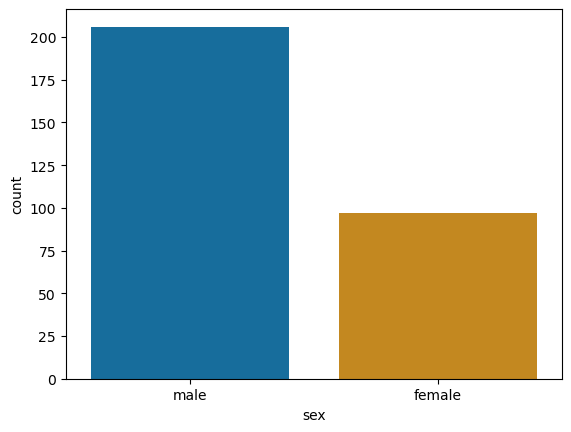

In [18]:
sns.countplot(x='sex', hue='sex', data=df, palette='colorblind', legend=False)

`barplot` can be used to see a numerical variable (e.g. `chol`) with respect to a categorical one (e.g. `sex` or `cp`)

<Axes: xlabel='cp', ylabel='chol'>

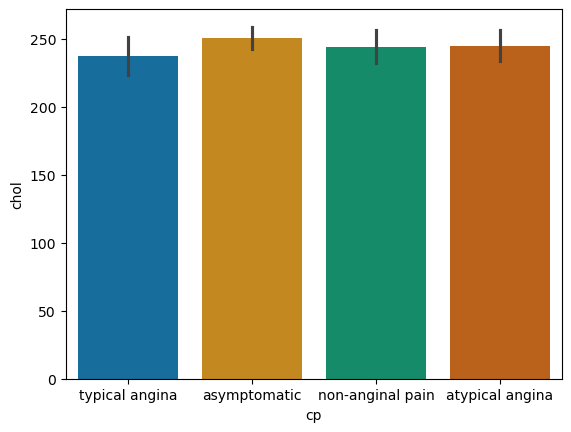

In [19]:
sns.barplot(x='cp', hue='cp', y='chol', data=df, palette="colorblind")

`Boxplots` can be easily visualized with python. The corresponding seaborn function will automatically compute:  

- the *median* (middle line in the box)
- *inter-quartile range* (IQR, top and bottom parts of the boxes - this is where 50% of your data is)
- *whiskers* (the black lines extending to the lowest and highest values that are still within 1.5*IQR)
- *outliers* (any observations outside the whiskers)

`Violin plots` are another way to visualise continuous variables. 

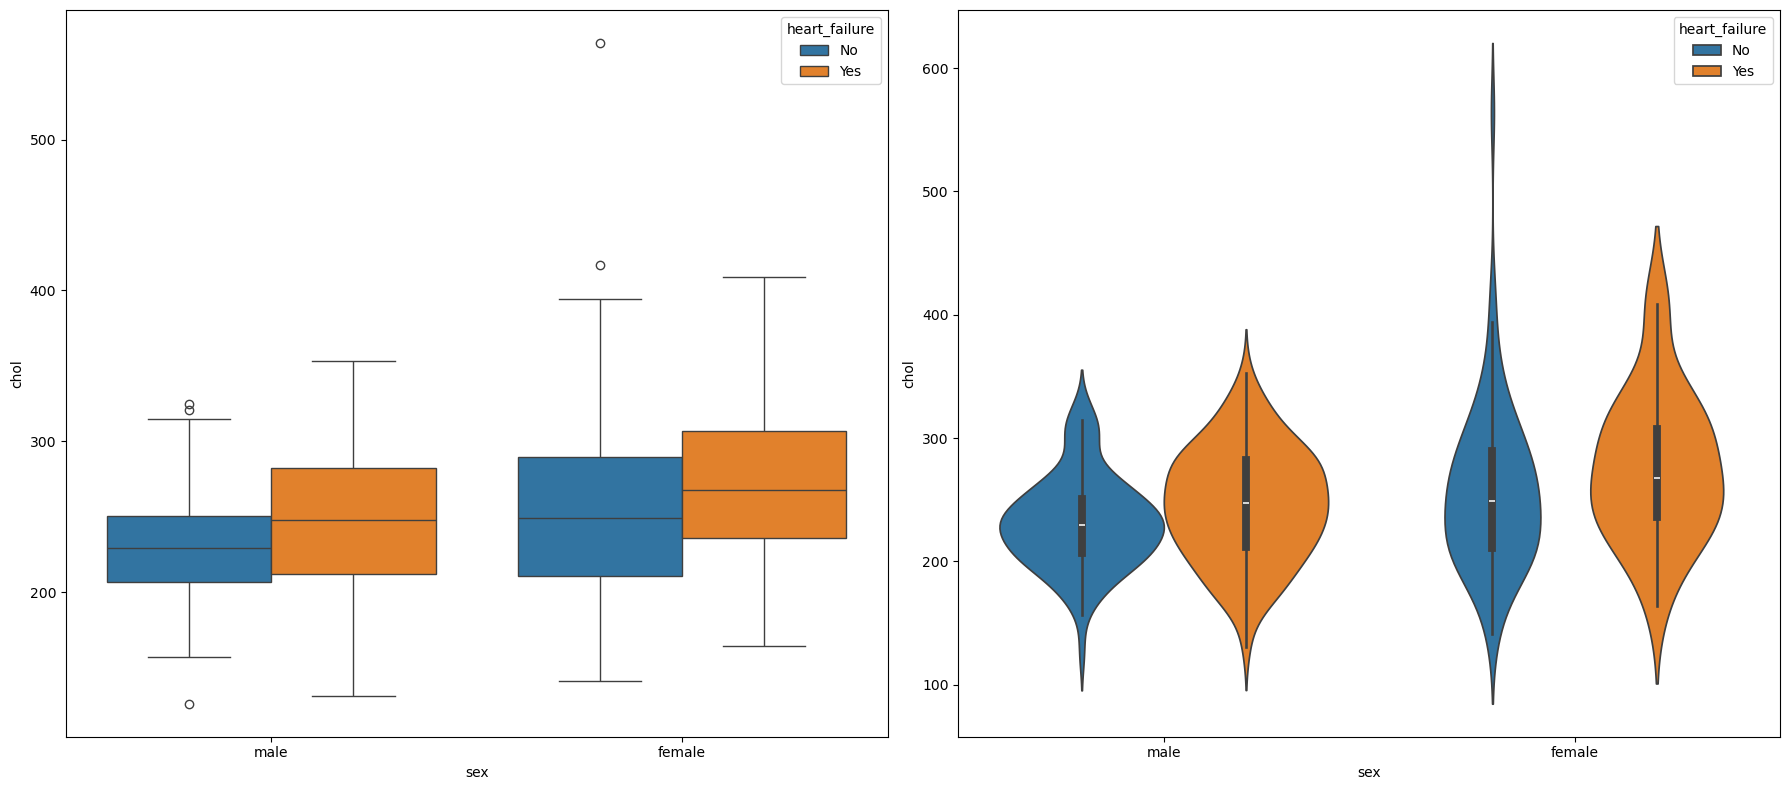

In [20]:
# Create subplots for boxplot and violinplot
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

sns.boxplot(data = df,
            x='sex', 
            y='chol', 
            hue='heart_failure',
            ax = axes[0]
             
        )

sns.violinplot(data = df,
            x='sex', 
            y='chol', 
            hue='heart_failure',
            ax = axes[1]
        )
    

# Adjust layout and show the figure
plt.tight_layout()
plt.show()

## Exercise 2: countplot and boxplot

Task:
1. Draw a **countplot** of the chest pain type (`cp`), colored by `heart_failure`.
2. Draw a **boxplot** of the maximum heart rate (`thalach`) for patients with and without heart disease (`heart_failure`).
3. Which chest pain type is most common in patients with heart disease? Which group has the higher maximum heart rate?

Hint: look at the `countplot` and `boxplot` cells above. You only need to change the variable names (`x`, `y`, `hue`).

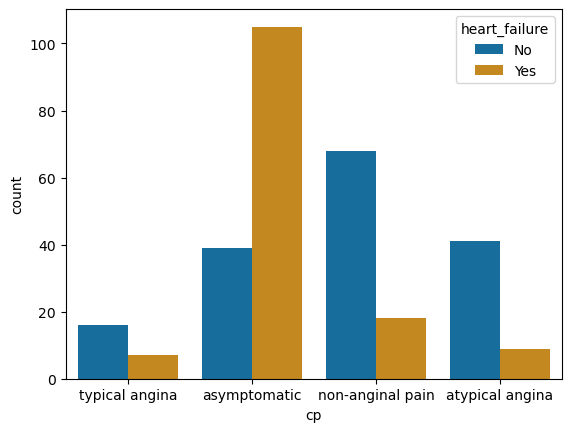

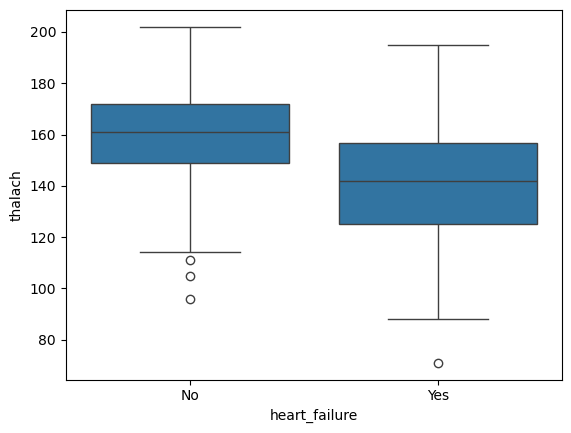

In [21]:
# 1. Countplot of cp, colored by heart_failure
sns.countplot(x='cp', hue='heart_failure', data=df, palette='colorblind')
plt.show()

# 2. Boxplot of thalach per heart_failure
sns.boxplot(x='heart_failure', y='thalach', data=df)
plt.show()

# 3. Interpretation
# Most patients with heart disease have asymptomatic chest pain.
# Patients without heart disease reach a higher maximum heart rate.

### Additional material: Some more advanced figures

A `heatmap` displays a matrix of values as a grid of colored cells, where the color encodes the magnitude. It is well suited to showing counts across two categorical variables. Here, we use it to show how many patients report each chest pain type, split by sex.

To create a heatmap, the data must first be in matrix form, with one categorical variable as rows and the other as columns. We prepare it in two steps:

1. `df.groupby(["sex", "cp"]).size()` counts the patients in each combination of sex and chest pain type. The result is a Series with a two-level index.
2. `.unstack()` moves the inner index level (`cp`) into the columns. The result is a table with sex as rows, chest pain types as columns, and the counts as cell values.

In [22]:
heatmap_data = df.groupby(["sex", "cp"]).size()

In [23]:
heatmap_data

sex     cp              
female  asymptomatic         40
        atypical angina      18
        non-anginal pain     35
        typical angina        4
male    asymptomatic        104
        atypical angina      32
        non-anginal pain     51
        typical angina       19
dtype: int64

In [24]:
heatmap_data = df.groupby(["sex", "cp"]).size().unstack()

In [25]:
heatmap_data.index

Index(['female', 'male'], dtype='object', name='sex')

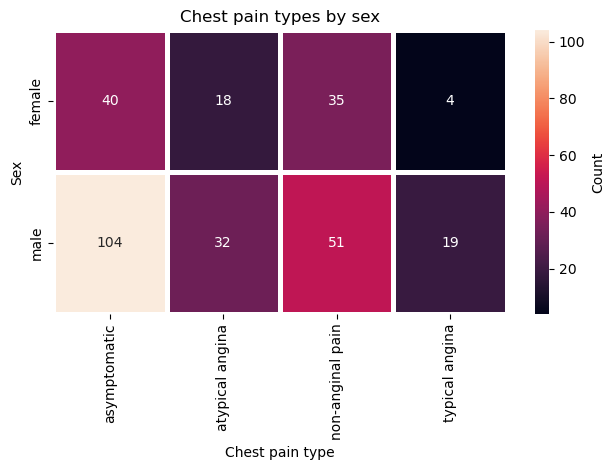

In [26]:
sns.heatmap(
    heatmap_data,
    annot=True,          # print the counts in the cells
    fmt="d",             # integer format, since these are counts
    linewidths=2.5,
    cbar_kws={"label": "Count"}
)

plt.title("Chest pain types by sex")
plt.xlabel("Chest pain type")
plt.ylabel("Sex")
plt.tight_layout()
plt.show()

A `pairplot` creates a grid of plots that shows the pairwise relationships between several numerical variables at once. Each off-diagonal panel is a scatter plot of two variables, and each diagonal panel shows the distribution of a single variable. This makes it a quick way to spot trends, clusters, and outliers before looking at individual relationships in detail.

Here, we plot `chol`, `trestbps`, and `age`, and color the points by heart disease status using hue. This lets us see whether patients with and without heart disease separate in any combination of these variables, and whether the distributions differ.

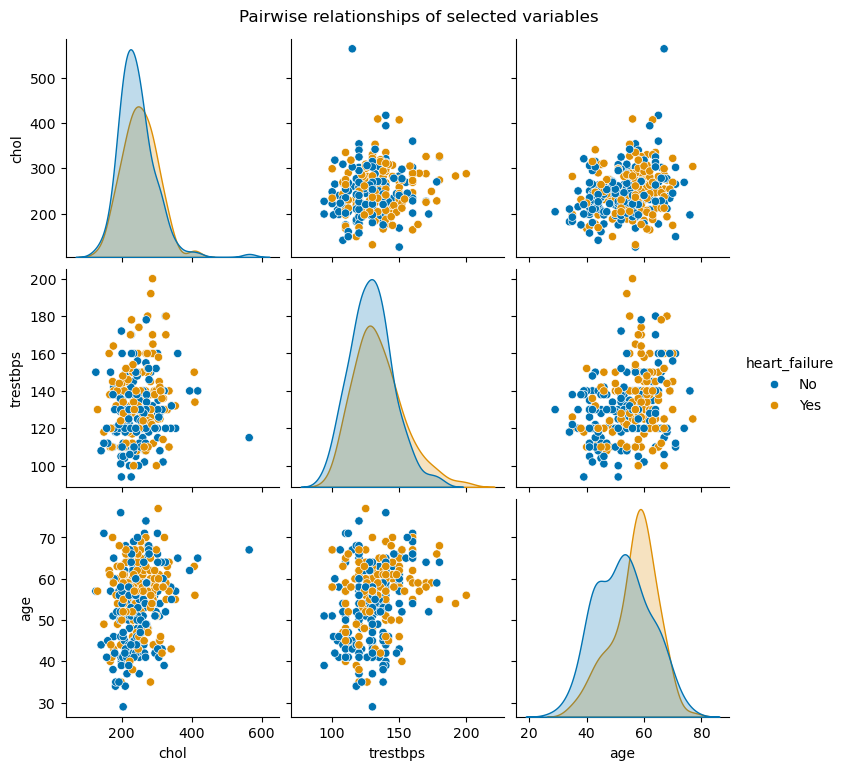

In [27]:
# Define the variables that will be plotted
biomarkers = df[["chol","trestbps", "age", "heart_failure"]]

# Plot Pairwise relationships between selected variables, colored by heart disease status
fig_correlation = sns.pairplot(biomarkers, 
                               hue ="heart_failure", 
                               palette="colorblind"
                            )

plt.suptitle("Pairwise relationships of selected variables", y=1.02)
plt.show()

Many datasets, including ours, are in wide format: each row is one patient and each variable has its own column. This is convenient for looking at a patient, but plotting libraries like seaborn expect long format, where one column holds the variable name and another holds the value.

melt converts the data from wide to long. Each patient's row becomes one row per selected feature. The heart_failure column is kept as an identifier (id_vars), the feature names go into a new measure column, and their values go into a new value column.

We need this because seaborn maps columns onto plot aesthetics such as x, y, and hue. With the long format, measure can be mapped to hue, so several variables can be drawn in a single call with no loop over columns. The same structure also makes summaries simple: `groupby(["heart_failure", "measure"])` computes the median of every feature per group in one step.

In [28]:
# Select some interesting features
features = ["chol", "trestbps", 'age', 'thalach']

long_measures = df.melt(
    id_vars="heart_failure",
    value_vars=features,
    var_name="measure",
    value_name="value"
)

print(long_measures)


     heart_failure  measure  value
0               No     chol    233
1              Yes     chol    286
2              Yes     chol    229
3               No     chol    250
4               No     chol    204
...            ...      ...    ...
1207           Yes  thalach    132
1208           Yes  thalach    141
1209           Yes  thalach    115
1210           Yes  thalach    174
1211            No  thalach    173

[1212 rows x 3 columns]


In [29]:
summary_long = (long_measures.groupby(["heart_failure", "measure"])["value"].median())

print(summary_long)

heart_failure  measure 
No             age          52.0
               chol        234.5
               thalach     161.0
               trestbps    130.0
Yes            age          58.0
               chol        249.0
               thalach     142.0
               trestbps    130.0
Name: value, dtype: float64


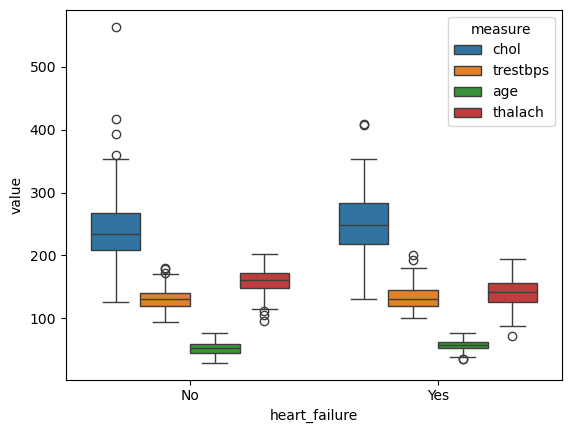

In [30]:
sns.boxplot(data=long_measures, x="heart_failure", y="value", hue="measure")
plt.show()